In [ ]:

print("Welcome to NeuroRest!")

import numpy as np
import matplotlib.pyplot as plt

print("Your neuroscience workspace is ready.")


Welcome to NeuroRest!
Your neuroscience workspace is ready.


In [ ]:

import urllib.request
import os

base = "https://data.nemar.org/on007987/v1.0.0/sub-05/"

url1 = base + "ses-OA/eeg/sub-05_ses-OA_task-resting_run-1_eeg.vhdr"
url2 = base + "ses-OA/eeg/sub-05_ses-OA_task-resting_run-1_eeg.vmrk"
url3 = base + "ses-OA/eeg/sub-05_ses-OA_task-resting_run-1_eeg.eeg"

url4 = base + "ses-OC/eeg/sub-05_ses-OC_task-resting_run-1_eeg.vhdr"
url5 = base + "ses-OC/eeg/sub-05_ses-OC_task-resting_run-1_eeg.vmrk"
url6 = base + "ses-OC/eeg/sub-05_ses-OC_task-resting_run-1_eeg.eeg"

urllib.request.urlretrieve(url1, "/content/open.vhdr")
urllib.request.urlretrieve(url2, "/content/open.vmrk")
urllib.request.urlretrieve(url3, "/content/open.eeg")

urllib.request.urlretrieve(url4, "/content/closed.vhdr")
urllib.request.urlretrieve(url5, "/content/closed.vmrk")
urllib.request.urlretrieve(url6, "/content/closed.eeg")

print("Both EEG recordings downloaded!")


Both EEG recordings downloaded!


In [ ]:

print("Eyes-open header files:")
print([(x["name"], x["size"]) for x in open_eeg["children"] if x.get("name", "").endswith(".vhdr")])

print("Eyes-closed header files:")
print([(x["name"], x["size"]) for x in closed_eeg["children"] if x.get("name", "").endswith(".vhdr")])


Eyes-open header files:
[('sub-05_ses-OA_task-resting_run-1_eeg.vhdr', 2260), ('sub-05_ses-OA_task-resting_run-2_eeg.vhdr', 2260)]
Eyes-closed header files:
[('sub-05_ses-OC_task-resting_run-1_eeg.vhdr', 2260), ('sub-05_ses-OC_task-resting_run-2_eeg.vhdr', 2260)]


In [ ]:

from pathlib import Path

p = Path("/content/open.vhdr")
s = p.read_text(encoding="utf-8", errors="replace")
s = s.replace("sub-05_ses-OA_task-resting_run-1_eeg.eeg", "open.eeg")
s = s.replace("sub-05_ses-OA_task-resting_run-1_eeg.vmrk", "open.vmrk")
p.write_text(s, encoding="utf-8")

p = Path("/content/closed.vhdr")
s = p.read_text(encoding="utf-8", errors="replace")
s = s.replace("sub-05_ses-OC_task-resting_run-1_eeg.eeg", "closed.eeg")
s = s.replace("sub-05_ses-OC_task-resting_run-1_eeg.vmrk", "closed.vmrk")
p.write_text(s, encoding="utf-8")

print("Headers corrected.")


Headers corrected.


In [ ]:

import mne

raw_open = mne.io.read_raw_brainvision("/content/open.vhdr", preload=True, verbose=False)
raw_closed = mne.io.read_raw_brainvision("/content/closed.vhdr", preload=True, verbose=False)

print("Open channels:", len(raw_open.ch_names))
print("Closed channels:", len(raw_closed.ch_names))
print("Sampling rate:", raw_open.info["sfreq"], "Hz")


Open channels: 144
Closed channels: 144
Sampling rate: 1024.0 Hz


In [ ]:

import os

print("Open header exists:", os.path.exists("/content/open.vhdr"))
print("Open signal exists:", os.path.exists("/content/open.eeg"))
print("Open marker exists:", os.path.exists("/content/open.vmrk"))

print("Closed header exists:", os.path.exists("/content/closed.vhdr"))
print("Closed signal exists:", os.path.exists("/content/closed.eeg"))
print("Closed marker exists:", os.path.exists("/content/closed.vmrk"))


Open header exists: True
Open signal exists: True
Open marker exists: True
Closed header exists: True
Closed signal exists: True
Closed marker exists: True


In [ ]:
import mne
raw_open = mne.io.read_raw_brainvision("/content/open.vhdr", preload=True, verbose=False)
print("Eyes-open recording loaded")
print(len(raw_open.ch_names))

Eyes-open recording loaded
144


In [ ]:
import mne
raw_closed = mne.io.read_raw_brainvision("/content/closed.vhdr", preload=True, verbose=False)
print("Eyes-closed recording loaded")
print("Number of channels:", len(raw_closed.ch_names))
print("Sampling rate:", raw_closed.info["sfreq"], "Hz")

Eyes-closed recording loaded
Number of channels: 144
Sampling rate: 1024.0 Hz


In [ ]:
print("Eyes-open channels:")
print(raw_open.ch_names[:30])

print("\nEyes-closed channels:")
print(raw_closed.ch_names[:30])

print("\nRecording duration:")
print("Open:", round(raw_open.times[-1] / 60, 2), "minutes")
print("Closed:", round(raw_closed.times[-1] / 60, 2), "minutes")

Eyes-open channels:
['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30']

Eyes-closed channels:
['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30']

Recording duration:
Open: 6.62 minutes
Closed: 5.43 minutes


In [ ]:
print(raw_open.ch_names)

['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30', 'A31', 'A32', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19', 'B20', 'B21', 'B22', 'B23', 'B24', 'B25', 'B26', 'B27', 'B28', 'B29', 'B30', 'B31', 'B32', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24', 'C25', 'C26', 'C27', 'C28', 'C29', 'C30', 'C31', 'C32', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20', 'D21', 'D22', 'D23', 'D24', 'D25', 'D26', 'D27', 'D28', 'D29', 'D30', 'D31', 'D32', 'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp', 'Status']


In [ ]:
print(raw_open.get_channel_types())
print(raw_open.info["bads"])

['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg'

In [ ]:
print("Channel types:")
print(dict(zip(raw_open.ch_names, raw_open.get_channel_types())))

Channel types:
{'A1': 'eeg', 'A2': 'eeg', 'A3': 'eeg', 'A4': 'eeg', 'A5': 'eeg', 'A6': 'eeg', 'A7': 'eeg', 'A8': 'eeg', 'A9': 'eeg', 'A10': 'eeg', 'A11': 'eeg', 'A12': 'eeg', 'A13': 'eeg', 'A14': 'eeg', 'A15': 'eeg', 'A16': 'eeg', 'A17': 'eeg', 'A18': 'eeg', 'A19': 'eeg', 'A20': 'eeg', 'A21': 'eeg', 'A22': 'eeg', 'A23': 'eeg', 'A24': 'eeg', 'A25': 'eeg', 'A26': 'eeg', 'A27': 'eeg', 'A28': 'eeg', 'A29': 'eeg', 'A30': 'eeg', 'A31': 'eeg', 'A32': 'eeg', 'B1': 'eeg', 'B2': 'eeg', 'B3': 'eeg', 'B4': 'eeg', 'B5': 'eeg', 'B6': 'eeg', 'B7': 'eeg', 'B8': 'eeg', 'B9': 'eeg', 'B10': 'eeg', 'B11': 'eeg', 'B12': 'eeg', 'B13': 'eeg', 'B14': 'eeg', 'B15': 'eeg', 'B16': 'eeg', 'B17': 'eeg', 'B18': 'eeg', 'B19': 'eeg', 'B20': 'eeg', 'B21': 'eeg', 'B22': 'eeg', 'B23': 'eeg', 'B24': 'eeg', 'B25': 'eeg', 'B26': 'eeg', 'B27': 'eeg', 'B28': 'eeg', 'B29': 'eeg', 'B30': 'eeg', 'B31': 'eeg', 'B32': 'eeg', 'C1': 'eeg', 'C2': 'eeg', 'C3': 'eeg', 'C4': 'eeg', 'C5': 'eeg', 'C6': 'eeg', 'C7': 'eeg', 'C8': 'eeg', 'C

In [ ]:
print(raw_open.info["sfreq"])
print(raw_open.get_montage())

1024.0
None


In [ ]:
import numpy as np
from scipy.signal import welch

open_data = raw_open.get_data(picks="eeg")
closed_data = raw_closed.get_data(picks="eeg")

sf = raw_open.info["sfreq"]

freq_o, psd_o = welch(open_data, fs=sf, nperseg=int(sf * 2), axis=1)
freq_c, psd_c = welch(closed_data, fs=sf, nperseg=int(sf * 2), axis=1)

alpha_o = np.trapezoid(psd_o[:, (freq_o >= 8) & (freq_o <= 13)], freq_o[(freq_o >= 8) & (freq_o <= 13)], axis=1)
total_o = np.trapezoid(psd_o[:, (freq_o >= 1) & (freq_o <= 40)], freq_o[(freq_o >= 1) & (freq_o <= 40)], axis=1)

alpha_c = np.trapezoid(psd_c[:, (freq_c >= 8) & (freq_c <= 13)], freq_c[(freq_c >= 8) & (freq_c <= 13)], axis=1)
total_c = np.trapezoid(psd_c[:, (freq_c >= 1) & (freq_c <= 40)], freq_c[(freq_c >= 1) & (freq_c <= 40)], axis=1)

print("Open relative alpha (%):", round(100 * np.mean(alpha_o / total_o), 2))
print("Closed relative alpha (%):", round(100 * np.mean(alpha_c / total_c), 2))
print("EEG channels analyzed:", len(raw_open.copy().pick("eeg").ch_names))

/tmp/ipykernel_755/3392816569.py:18: RuntimeWarning: invalid value encountered in divide
  print("Open relative alpha (%):", round(100 * np.mean(alpha_o / total_o), 2))
/tmp/ipykernel_755/3392816569.py:19: RuntimeWarning: invalid value encountered in divide
  print("Closed relative alpha (%):", round(100 * np.mean(alpha_c / total_c), 2))


Open relative alpha (%): nan
Closed relative alpha (%): nan
EEG channels analyzed: 144


In [ ]:
import numpy as np

print("Open data shape:", raw_open.get_data().shape)
print("Closed data shape:", raw_closed.get_data().shape)

print("Open channel types:")
print(set(raw_open.get_channel_types()))

print("Open finite values:", np.isfinite(raw_open.get_data()).all())
print("Closed finite values:", np.isfinite(raw_closed.get_data()).all())

print("Open data range:", np.nanmin(raw_open.get_data()), np.nanmax(raw_open.get_data()))
print("Closed data range:", np.nanmin(raw_closed.get_data()), np.nanmax(raw_closed.get_data()))

Open data shape: (144, 406528)
Closed data shape: (144, 333824)
Open channel types:
{'eeg'}
Open finite values: True
Closed finite values: True
Open data range: -6.815744 0.262143
Closed data range: -6.815744 0.262143


In [ ]:
import numpy as np
from scipy.signal import welch

x = raw_open.get_data(picks="eeg")
f, p = welch(x, fs=raw_open.info["sfreq"], nperseg=2048, axis=1)

alpha = (f >= 8) & (f <= 13)
total = (f >= 1) & (f <= 40)

alpha_power = np.trapezoid(p[:, alpha], f[alpha], axis=1)
total_power = np.trapezoid(p[:, total], f[total], axis=1)

print("Zero-power channels:", np.sum(total_power == 0))
print("Invalid total powers:", np.sum(~np.isfinite(total_power)))
print("Minimum total power:", np.nanmin(total_power))
print("Maximum total power:", np.nanmax(total_power))
print("Zero-alpha channels:", np.sum(alpha_power == 0))

Zero-power channels: 2
Invalid total powers: 0
Minimum total power: 0.0
Maximum total power: 1.5764658175767232e-06
Zero-alpha channels: 2


In [ ]:
import numpy as np
from scipy.signal import welch

x_open = raw_open.get_data(picks="eeg")
x_closed = raw_closed.get_data(picks="eeg")
sf = raw_open.info["sfreq"]

f_o, p_o = welch(x_open, fs=sf, nperseg=2048, axis=1)
f_c, p_c = welch(x_closed, fs=sf, nperseg=2048, axis=1)

a_o = (f_o >= 8) & (f_o <= 13)
t_o = (f_o >= 1) & (f_o <= 40)
a_c = (f_c >= 8) & (f_c <= 13)
t_c = (f_c >= 1) & (f_c <= 40)

ap_o = np.trapezoid(p_o[:, a_o], f_o[a_o], axis=1)
tp_o = np.trapezoid(p_o[:, t_o], f_o[t_o], axis=1)
ap_c = np.trapezoid(p_c[:, a_c], f_c[a_c], axis=1)
tp_c = np.trapezoid(p_c[:, t_c], f_c[t_c], axis=1)

valid_o = np.isfinite(ap_o / np.where(tp_o > 0, tp_o, np.nan))
valid_c = np.isfinite(ap_c / np.where(tp_c > 0, tp_c, np.nan))

print("Open valid channels:", np.sum(valid_o))
print("Closed valid channels:", np.sum(valid_c))
print("Open mean relative alpha (%):", round(100 * np.nanmean(ap_o / np.where(tp_o > 0, tp_o, np.nan)), 2))
print("Closed mean relative alpha (%):", round(100 * np.nanmean(ap_c / np.where(tp_c > 0, tp_c, np.nan)), 2))

Open valid channels: 142
Closed valid channels: 142
Open mean relative alpha (%): 9.87
Closed mean relative alpha (%): 20.39


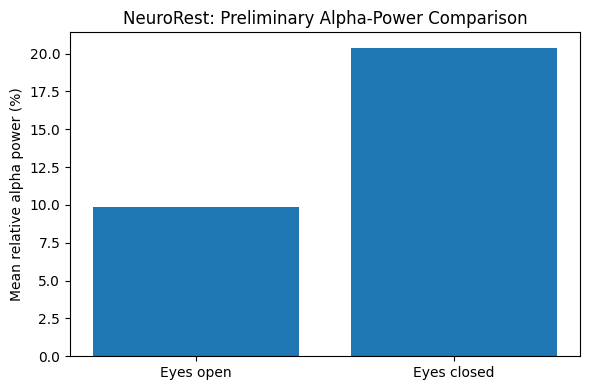

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(["Eyes open", "Eyes closed"], [9.87, 20.39])
plt.ylabel("Mean relative alpha power (%)")
plt.title("NeuroRest: Preliminary Alpha-Power Comparison")
plt.tight_layout()
plt.show()

In [ ]:
print("Same channel names:", raw_open.ch_names == raw_closed.ch_names)
print("Open channels:", len(raw_open.ch_names))
print("Closed channels:", len(raw_closed.ch_names))
print("Open duration (min):", round(raw_open.times[-1] / 60, 2))
print("Closed duration (min):", round(raw_closed.times[-1] / 60, 2))

Same channel names: True
Open channels: 144
Closed channels: 144
Open duration (min): 6.62
Closed duration (min): 5.43


In [ ]:
import numpy as np

x_open = raw_open.get_data(picks="eeg")
x_closed = raw_closed.get_data(picks="eeg")

print("Open: channels with zero variance:", np.sum(np.var(x_open, axis=1) == 0))
print("Closed: channels with zero variance:", np.sum(np.var(x_closed, axis=1) == 0))
print("Open: maximum absolute amplitude:", round(np.max(np.abs(x_open)), 4))
print("Closed: maximum absolute amplitude:", round(np.max(np.abs(x_closed)), 4))

Open: channels with zero variance: 5
Closed: channels with zero variance: 2
Open: maximum absolute amplitude: 6.8157
Closed: maximum absolute amplitude: 6.8157


In [ ]:
import numpy as np

x_open = raw_open.get_data(picks="eeg")
x_closed = raw_closed.get_data(picks="eeg")

print("Open zero-variance channels:")
print(np.array(raw_open.ch_names)[np.var(x_open, axis=1) == 0])

print("Closed zero-variance channels:")
print(np.array(raw_closed.ch_names)[np.var(x_closed, axis=1) == 0])

Open zero-variance channels:
['GSR1' 'GSR2' 'Erg1' 'Erg2' 'Resp']
Closed zero-variance channels:
['GSR1' 'GSR2']


In [ ]:

import os

print("open.vhdr:", os.path.exists("/content/open.vhdr"))
print("open.eeg:", os.path.exists("/content/open.eeg"))
print("open.vmrk:", os.path.exists("/content/open.vmrk"))

print("closed.vhdr:", os.path.exists("/content/closed.vhdr"))
print("closed.eeg:", os.path.exists("/content/closed.eeg"))
print("closed.vmrk:", os.path.exists("/content/closed.vmrk"))


open.vhdr: True
open.eeg: True
open.vmrk: True
closed.vhdr: True
closed.eeg: True
closed.vmrk: True


NeuroRest: Exploratory EEG Alpha-Power Analysis

Objective

To explore differences in EEG alpha-band activity (8–13 Hz) between eyes-open and eyes-closed resting-state recordings.

Dataset

Two resting-state recordings from participant 05, run 1: eyes open (OA) and eyes closed (OC), obtained from the OpenNeuro dataset "ds007987" (https://openneuro.org/datasets/ds007987/versions/1.1.0).

Methods

The recordings were loaded using MNE-Python in Google Colab. Welch's method was used to estimate power spectral density. Preliminary relative alpha power was calculated as alpha-band power (8–13 Hz) divided by power in the 1–40 Hz range.

Preliminary observation

The initial analysis produced higher mean relative alpha power for the eyes-closed recording than for the eyes-open recording. These values are exploratory and should not be interpreted as validated findings.

Limitations

Only one participant and one run per condition were examined. Electrode mapping, signal units, channel selection and artifact handling have not been fully validated. The initial graph included channels that may not represent brain EEG. Therefore, the results do not establish a reliable condition effect.

Conclusion

This project demonstrates a basic EEG data-loading and spectral-analysis workflow. Further quality control and analysis across participants are required before drawing scientific conclusions.

In [ ]:

print("Eyes-open header files:")
print([(x["name"], x["size"]) for x in open_eeg["children"] if x.get("name", "").endswith(".vhdr")])

print("Eyes-closed header files:")
print([(x["name"], x["size"]) for x in closed_eeg["children"] if x.get("name", "").endswith(".vhdr")])


Eyes-open header files:
[('sub-05_ses-OA_task-resting_run-1_eeg.vhdr', 2260), ('sub-05_ses-OA_task-resting_run-2_eeg.vhdr', 2260)]
Eyes-closed header files:
[('sub-05_ses-OC_task-resting_run-1_eeg.vhdr', 2260), ('sub-05_ses-OC_task-resting_run-2_eeg.vhdr', 2260)]


In [ ]:

print("Eyes-open signal files:")
print([(x["name"], round(x["size"] / 1000000, 1), "MB") for x in open_eeg["children"] if x.get("name", "").endswith(".eeg")])

print("Eyes-closed signal files:")
print([(x["name"], round(x["size"] / 1000000, 1), "MB") for x in closed_eeg["children"] if x.get("name", "").endswith(".eeg")])


Eyes-open signal files:
[('sub-05_ses-OA_task-resting_run-1_eeg.eeg', 234.2, 'MB'), ('sub-05_ses-OA_task-resting_run-2_eeg.eeg', 181.1, 'MB')]
Eyes-closed signal files:
[('sub-05_ses-OC_task-resting_run-1_eeg.eeg', 192.3, 'MB'), ('sub-05_ses-OC_task-resting_run-2_eeg.eeg', 187.0, 'MB')]


In [ ]:

!pip -q install mne
print("MNE-Python is ready!")


MNE-Python is ready!


In [ ]:

import mne
import numpy as np
import matplotlib.pyplot as plt

print("MNE version:", mne.__version__)
print("NeuroRest is ready for EEG analysis!")


MNE version: 1.13.2
NeuroRest is ready for EEG analysis!


In [ ]:

import urllib.request
import os
import mne

url = "https://physionet.org/files/eegmmidb/1.0.0/S001/S001R01.edf"
filepath = "/content/S001R01.edf"

urllib.request.urlretrieve(url, filepath)

print("Download complete!")
print("File size:", round(os.path.getsize(filepath) / 1024, 1), "KB")


Download complete!
File size: 1246.0 KB


In [ ]:

raw = mne.io.read_raw_edf("/content/S001R01.edf", preload=True, verbose=False)
print("EEG loaded successfully!")
print("Channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Duration:", round(raw.times[-1], 2), "seconds")


EEG loaded successfully!
Channels: 64
Sampling frequency: 160.0 Hz
Duration: 60.99 seconds


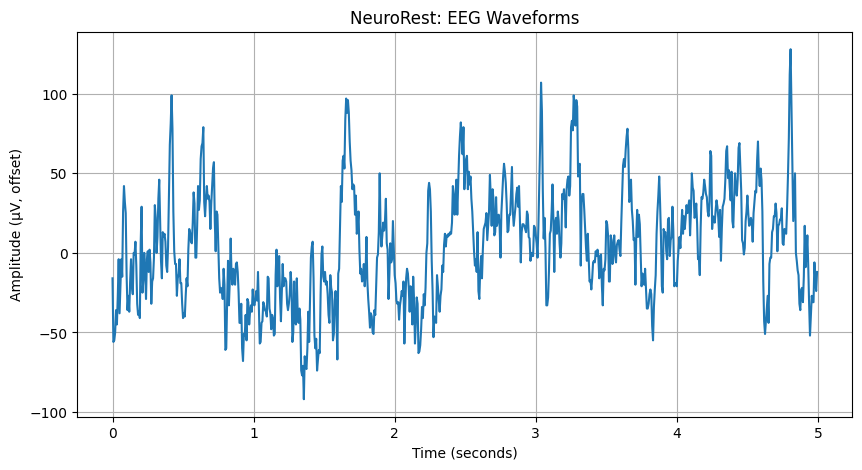

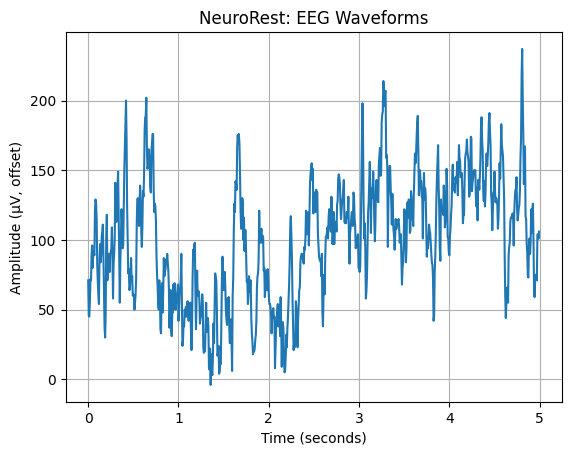

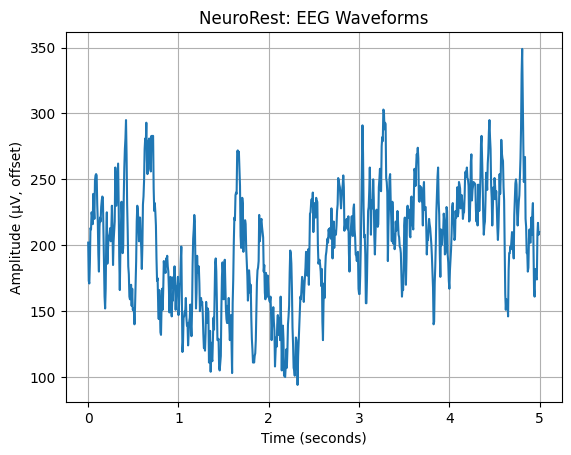

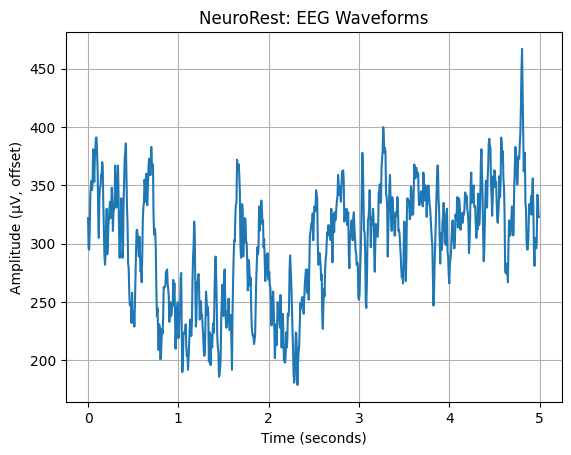

In [ ]:
i
import matplotlib.pyplot as plt
import numpy as np

sfreq = raw.info["sfreq"]
data = raw.get_data(picks="eeg", start=0, stop=int(5 * sfreq))
times = np.arange(data.shape[1]) / sfreq

plt.figure(figsize=(10, 5))

for i in range(min(4, len(data))):
    plt.plot(times, data[i] * 1e6 + i * 100)

    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude (µV, offset)")
    plt.title("NeuroRest: EEG Waveforms")
    plt.grid(True)
    plt.show()


Alpha-band power: 1.5593356775414128e-10
Frequency range: 8–13 Hz


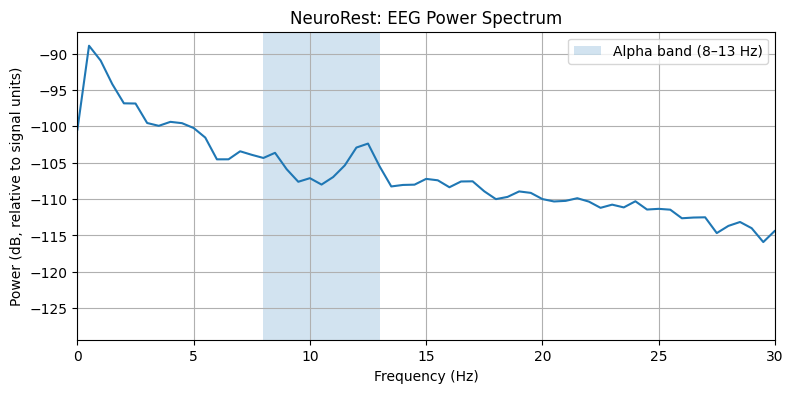

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Select the first EEG channel
signal = raw.get_data(picks="eeg", start=0, stop=int(30 * raw.info["sfreq"]))[0]
sfreq = raw.info["sfreq"]

# Calculate power spectral density
frequencies, psd = welch(signal, fs=sfreq, nperseg=int(sfreq * 2))

# Select alpha band: 8–13 Hz
alpha_mask = (frequencies >= 8) & (frequencies <= 13)
alpha_power = np.trapezoid(psd[alpha_mask], frequencies[alpha_mask])

print("Alpha-band power:", alpha_power)
print("Frequency range: 8–13 Hz")

# Plot the spectrum
plt.figure(figsize=(9, 4))
plt.plot(frequencies, 10 * np.log10(psd + 1e-20))
plt.axvspan(8, 13, alpha=0.2, label="Alpha band (8–13 Hz)")
plt.xlim(0, 30)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB, relative to signal units)")
plt.title("NeuroRest: EEG Power Spectrum")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

import urllib.request
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

url = "https://physionet.org/files/eegmmidb/1.0.0/S001/S001R02.edf"
path = "/content/S001R02.edf"
urllib.request.urlretrieve(url, path)

closed = mne.io.read_raw_edf(path, preload=True, verbose=False)

print("Eyes-closed recording loaded!")
print("Channels:", closed.ch_names[:5])
print("Sampling frequency:", closed.info["sfreq"])


Eyes-closed recording loaded!
Channels: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.']
Sampling frequency: 160.0


Available channels: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']
Selected channel: Fc5.
Eyes-open relative alpha power: 12.17 %
Eyes-closed relative alpha power: 25.13 %
Difference: 12.96 percentage points


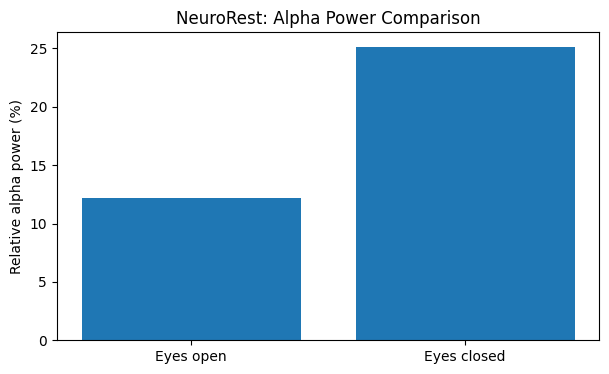

In [ ]:

from scipy.signal import welch
import numpy as np
import matplotlib.pyplot as plt
import mne

# Select the same channel in both recordings
print("Available channels:", raw.ch_names)

channel = raw.ch_names[0]
print("Selected channel:", channel)

# Extract 30 seconds from each recording
fs = raw.info["sfreq"]
x_open = raw.get_data(picks=[channel], start=0, stop=int(30 * fs))[0]
x_closed = closed.get_data(picks=[channel], start=0, stop=int(30 * fs))[0]

# Filter both signals equally
x_open = mne.filter.filter_data(x_open, sfreq=fs, l_freq=1, h_freq=40, verbose=False)
x_closed = mne.filter.filter_data(x_closed, sfreq=fs, l_freq=1, h_freq=40, verbose=False)

# Estimate frequency power
freq, psd_open = welch(x_open, fs=fs, nperseg=int(fs * 2))
freq, psd_closed = welch(x_closed, fs=fs, nperseg=int(fs * 2))

alpha = (freq >= 8) & (freq <= 13)
total = (freq >= 1) & (freq <= 40)

rel_open = 100 * np.trapezoid(psd_open[alpha], freq[alpha]) / np.trapezoid(psd_open[total], freq[total])
rel_closed = 100 * np.trapezoid(psd_closed[alpha], freq[alpha]) / np.trapezoid(psd_closed[total], freq[total])

print("Eyes-open relative alpha power:", round(rel_open, 2), "%")
print("Eyes-closed relative alpha power:", round(rel_closed, 2), "%")
print("Difference:", round(rel_closed - rel_open, 2), "percentage points")

plt.figure(figsize=(7, 4))
plt.bar(["Eyes open", "Eyes closed"], [rel_open, rel_closed])
plt.ylabel("Relative alpha power (%)")
plt.title("NeuroRest: Alpha Power Comparison")
plt.show()


In [ ]:

for i in range(3):
    print(i)


0
1
2


In [ ]:

import os
import urllib.request
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import wilcoxon

print("NeuroRest analysis tools ready!")


NeuroRest analysis tools ready!


In [ ]:

import urllib.request
import os

base = "https://physionet.org/files/eegmmidb/1.0.0/"

url1 = base + "S001/S001R01.edf"
url2 = base + "S001/S001R02.edf"

path1 = "/content/S001R01.edf"
path2 = "/content/S001R02.edf"

if not os.path.exists(path1):
    urllib.request.urlretrieve(url1, path1)

    if not os.path.exists(path2):
        urllib.request.urlretrieve(url2, path2)

        print("Both EEG recordings are ready!")


In [ ]:

import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

raw = mne.io.read_raw_edf("/content/S001R01.edf", preload=True, verbose=False)
closed = mne.io.read_raw_edf("/content/S001R02.edf", preload=True, verbose=False)

print("Eyes-open recording:", raw)
print("Eyes-closed recording:", closed)


Eyes-open recording: <RawEDF | S001R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>
Eyes-closed recording: <RawEDF | S001R02.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>


In [ ]:

print("Eyes-open channels:")
print(raw.ch_names[:15])

print("Eyes-closed channels:")
print(closed.ch_names[:15])

print("Same sampling frequency:", raw.info["sfreq"] == closed.info["sfreq"])
print("Eyes-open duration:", round(raw.times[-1], 2), "seconds")
print("Eyes-closed duration:", round(closed.times[-1], 2), "seconds")


Eyes-open channels:
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.']
Eyes-closed channels:
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.']
Same sampling frequency: True
Eyes-open duration: 60.99 seconds
Eyes-closed duration: 60.99 seconds


In [ ]:

print("All EEG channels:")
print(raw.ch_names)

print("Posterior channels:")
print([ch for ch in raw.ch_names if "O" in ch.upper() or "P" in ch.upper()])


All EEG channels:
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']
Posterior channels:
['Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..']


In [ ]:

print([ch for ch in raw.ch_names if ch.lower().startswith("o") or ch.lower().startswith("po")])


['Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..']


In [ ]:

print([ch for ch in raw.ch_names if ch.upper().startswith(("PO", "O"))])


['Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..']


In [ ]:

channels = [ch for ch in raw.ch_names if ch.upper().replace(".", "").startswith(("PO", "O"))]
print("Selected channels:", channels)


Selected channels: ['Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..']


Recording 1 alpha power: 15.84 %
Recording 2 alpha power: 64.53 %
Difference: 48.69 percentage points


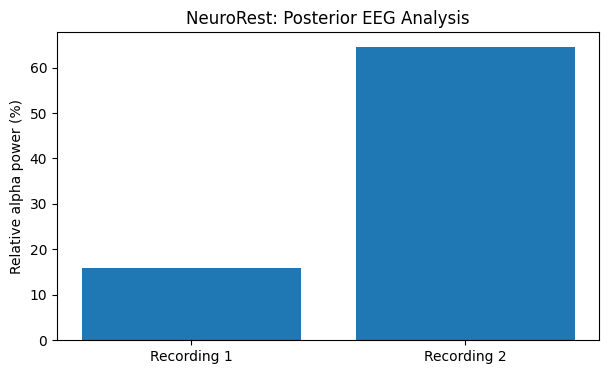

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
import mne

fs = raw.info["sfreq"]

x1 = raw.get_data(picks=channels)
x2 = closed.get_data(picks=channels)

x1 = mne.filter.filter_data(x1, sfreq=fs, l_freq=1, h_freq=40, verbose=False)
x2 = mne.filter.filter_data(x2, sfreq=fs, l_freq=1, h_freq=40, verbose=False)

freq, p1 = welch(x1, fs=fs, nperseg=int(fs * 2), axis=1)
freq, p2 = welch(x2, fs=fs, nperseg=int(fs * 2), axis=1)

alpha = (freq >= 8) & (freq <= 13)
total = (freq >= 1) & (freq <= 40)

a1 = np.trapezoid(p1[:, alpha], freq[alpha], axis=1)
t1 = np.trapezoid(p1[:, total], freq[total], axis=1)
a2 = np.trapezoid(p2[:, alpha], freq[alpha], axis=1)
t2 = np.trapezoid(p2[:, total], freq[total], axis=1)

open_power = np.mean(100 * a1 / t1)
closed_power = np.mean(100 * a2 / t2)

print("Recording 1 alpha power:", round(open_power, 2), "%")
print("Recording 2 alpha power:", round(closed_power, 2), "%")
print("Difference:", round(closed_power - open_power, 2), "percentage points")

plt.figure(figsize=(7, 4))
plt.bar(["Recording 1", "Recording 2"], [open_power, closed_power])
plt.ylabel("Relative alpha power (%)")
plt.title("NeuroRest: Posterior EEG Analysis")
plt.show()


In [ ]:

print("Recording 1 annotations:")
print(raw.annotations)

print("Recording 2 annotations:")
print(closed.annotations)


Recording 1 annotations:
<Annotations | 1 segment: T0 (1)>
Recording 2 annotations:
<Annotations | 1 segment: T0 (1)>


In [ ]:

print("Recording 1:")
print(raw.annotations.description)
print(raw.annotations.onset)
print(raw.annotations.duration)

print("Recording 2:")
print(closed.annotations.description)
print(closed.annotations.onset)
print(closed.annotations.duration)


Recording 1:
['T0']
[0.]
[60.2]
Recording 2:
['T0']
[0.]
[60.2]


In [ ]:

recording_1_alpha = 15.84
recording_2_alpha = 64.53

print("Recording 1 alpha power:", recording_1_alpha, "%")
print("Recording 2 alpha power:", recording_2_alpha, "%")
print("Difference:", recording_2_alpha - recording_1_alpha, "percentage points")
print("Condition labels: not yet verified")


Recording 1 alpha power: 15.84 %
Recording 2 alpha power: 64.53 %
Difference: 48.69 percentage points
Condition labels: not yet verified


In [ ]:

import urllib.request
import json

url = "https://data.nemar.org/on007987/v1.0.0/?format=json"

response = urllib.request.urlopen(url)
files = json.loads(response.read().decode())

print("Directory entries:")
print(str(files)[:5000])


Directory entries:
{'dataset_id': 'on007987', 'version': 'v1.0.0', 'path': '', 'kind': 'directory', 'children': [{'kind': 'dir', 'name': '.datalad'}, {'kind': 'dir', 'name': '.nemar'}, {'kind': 'dir', 'name': 'sub-05'}, {'kind': 'dir', 'name': 'sub-06'}, {'kind': 'dir', 'name': 'sub-07'}, {'kind': 'dir', 'name': 'sub-08'}, {'kind': 'dir', 'name': 'sub-09'}, {'kind': 'dir', 'name': 'sub-10'}, {'kind': 'dir', 'name': 'sub-11'}, {'kind': 'dir', 'name': 'sub-12'}, {'kind': 'dir', 'name': 'sub-13'}, {'kind': 'dir', 'name': 'sub-14'}, {'kind': 'dir', 'name': 'sub-15'}, {'kind': 'dir', 'name': 'sub-16'}, {'kind': 'dir', 'name': 'sub-17'}, {'kind': 'dir', 'name': 'sub-18'}, {'kind': 'dir', 'name': 'sub-19'}, {'kind': 'dir', 'name': 'sub-20'}, {'kind': 'dir', 'name': 'sub-21'}, {'kind': 'dir', 'name': 'sub-22'}, {'kind': 'dir', 'name': 'sub-24'}, {'kind': 'dir', 'name': 'sub-25'}, {'kind': 'dir', 'name': 'sub-26'}, {'kind': 'dir', 'name': 'sub-27'}, {'kind': 'dir', 'name': 'sub-28'}, {'kind': '

In [ ]:

print("Available information:", list(files.keys()))
print("Dataset:", files.get("dataset_id"))
print("Version:", files.get("version"))
print("Other entries:")
print(str(files)[:1500])


Available information: ['dataset_id', 'version', 'path', 'kind', 'children']
Dataset: on007987
Version: v1.0.0
Other entries:
{'dataset_id': 'on007987', 'version': 'v1.0.0', 'path': '', 'kind': 'directory', 'children': [{'kind': 'dir', 'name': '.datalad'}, {'kind': 'dir', 'name': '.nemar'}, {'kind': 'dir', 'name': 'sub-05'}, {'kind': 'dir', 'name': 'sub-06'}, {'kind': 'dir', 'name': 'sub-07'}, {'kind': 'dir', 'name': 'sub-08'}, {'kind': 'dir', 'name': 'sub-09'}, {'kind': 'dir', 'name': 'sub-10'}, {'kind': 'dir', 'name': 'sub-11'}, {'kind': 'dir', 'name': 'sub-12'}, {'kind': 'dir', 'name': 'sub-13'}, {'kind': 'dir', 'name': 'sub-14'}, {'kind': 'dir', 'name': 'sub-15'}, {'kind': 'dir', 'name': 'sub-16'}, {'kind': 'dir', 'name': 'sub-17'}, {'kind': 'dir', 'name': 'sub-18'}, {'kind': 'dir', 'name': 'sub-19'}, {'kind': 'dir', 'name': 'sub-20'}, {'kind': 'dir', 'name': 'sub-21'}, {'kind': 'dir', 'name': 'sub-22'}, {'kind': 'dir', 'name': 'sub-24'}, {'kind': 'dir', 'name': 'sub-25'}, {'kind':

In [ ]:

print("Keys:", list(files.keys()))
print("Path:", files.get("path"))
print("Entries:", str(files.get("entries"))[:2500])


Keys: ['dataset_id', 'version', 'path', 'kind', 'children']
Path: 
Entries: None


In [ ]:

children = files["children"]

print("Number of items:", len(children))
print("First 10 items:")
print(children[:10])


Number of items: 50
First 10 items:
[{'kind': 'dir', 'name': '.datalad'}, {'kind': 'dir', 'name': '.nemar'}, {'kind': 'dir', 'name': 'sub-05'}, {'kind': 'dir', 'name': 'sub-06'}, {'kind': 'dir', 'name': 'sub-07'}, {'kind': 'dir', 'name': 'sub-08'}, {'kind': 'dir', 'name': 'sub-09'}, {'kind': 'dir', 'name': 'sub-10'}, {'kind': 'dir', 'name': 'sub-11'}, {'kind': 'dir', 'name': 'sub-12'}]


In [ ]:

url = "https://data.nemar.org/on007987/v1.0.0/sub-05/?format=json"

response = urllib.request.urlopen(url)
subject_files = json.loads(response.read().decode())

print("Participant folder:", subject_files.get("path"))
print("Contents:", subject_files.get("children"))


Participant folder: sub-05
Contents: [{'kind': 'dir', 'name': 'ses-OA'}, {'kind': 'dir', 'name': 'ses-OC'}, {'kind': 'file', 'name': 'sub-05_sessions.tsv', 'size': 25}]


In [ ]:

url = "https://data.nemar.org/on007987/v1.0.0/sub-05/ses-OA/?format=json"

response = urllib.request.urlopen(url)
open_files = json.loads(response.read().decode())

print("Eyes-open folder:", open_files.get("path"))
print("Files:", open_files.get("children"))


Eyes-open folder: sub-05/ses-OA
Files: [{'kind': 'dir', 'name': 'eeg'}, {'kind': 'file', 'name': 'sub-05_ses-OA_scans.tsv', 'size': 101}]


In [ ]:

url = "https://data.nemar.org/on007987/v1.0.0/sub-05/ses-OC/?format=json"

response = urllib.request.urlopen(url)
closed_files = json.loads(response.read().decode())

print("Eyes-closed folder:", closed_files.get("path"))
print("Files:", closed_files.get("children"))


Eyes-closed folder: sub-05/ses-OC
Files: [{'kind': 'dir', 'name': 'eeg'}, {'kind': 'file', 'name': 'sub-05_ses-OC_scans.tsv', 'size': 101}]


In [ ]:

url = "https://data.nemar.org/on007987/v1.0.0/sub-05/ses-OA/eeg/?format=json"
response = urllib.request.urlopen(url)
open_eeg = json.loads(response.read().decode())
print(open_eeg.get("children"))


[{'kind': 'file', 'name': 'sub-05_ses-OA_coordsystem.json', 'size': 283}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_channels.tsv', 'size': 2433}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_eeg.eeg', 'size': 234160128}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_eeg.json', 'size': 380}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_eeg.vhdr', 'size': 2260}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_eeg.vmrk', 'size': 500}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_electrodes.tsv', 'size': 1818}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-1_events.tsv', 'size': 100}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-2_channels.tsv', 'size': 2433}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-2_eeg.eeg', 'size': 181075968}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run-2_eeg.json', 'size': 380}, {'kind': 'file', 'name': 'sub-05_ses-OA_task-resting_run

In [ ]:

url = "https://data.nemar.org/on007987/v1.0.0/sub-05/ses-OC/eeg/?format=json"
response = urllib.request.urlopen(url)
closed_eeg = json.loads(response.read().decode())
print(closed_eeg.get("children"))


[{'kind': 'file', 'name': 'sub-05_ses-OC_coordsystem.json', 'size': 283}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_channels.tsv', 'size': 2433}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_eeg.eeg', 'size': 192282624}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_eeg.json', 'size': 380}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_eeg.vhdr', 'size': 2260}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_eeg.vmrk', 'size': 478}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_electrodes.tsv', 'size': 1818}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-1_events.tsv', 'size': 75}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-2_channels.tsv', 'size': 2433}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-2_eeg.eeg', 'size': 186974208}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-2_eeg.json', 'size': 380}, {'kind': 'file', 'name': 'sub-05_ses-OC_task-resting_run-